<a href="https://colab.research.google.com/github/DebashishTiwary/MLBasics/blob/main/titanic_ANN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

In [2]:
df = pd.read_csv('/content/Titanic-Dataset.csv')

In [3]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [13]:
df_clean=df.copy()

In [14]:
df_clean=df_clean.drop(['Cabin','Ticket','Name','PassengerId'],axis=1)

In [15]:
df_clean.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


In [16]:
df_clean=pd.get_dummies(df_clean,columns=['Pclass','Sex','Embarked'],dtype=int)

In [17]:
df_clean.head()

,Survived,Age,SibSp,Parch,Fare,Pclass_1,Pclass_2,Pclass_3,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,0,22.0,1,0,7.2500,0,0,1,0,1,0,0,1
1,1,38.0,1,0,71.2833,1,0,0,1,0,1,0,0
2,1,26.0,0,0,7.9250,0,0,1,1,0,0,0,1
3,1,35.0,1,0,53.1000,1,0,0,1,0,0,0,1
4,0,35.0,0,0,8.0500,0,0,1,0,1,0,0,1


In [18]:
from sklearn.preprocessing import StandardScaler

scaler=StandardScaler()

In [19]:
df_clean['Fare'] = np.log1p(df_clean['Fare'])

In [20]:
df_clean['Age'] = df_clean['Age'].fillna(df_clean['Age'].median())

In [21]:
std_columns=['Age','SibSp','Parch','Fare']
df_clean[std_columns]=scaler.fit_transform(df_clean[std_columns])

In [22]:
df_clean.head()

,Survived,Age,SibSp,Parch,Fare,Pclass_1,Pclass_2,Pclass_3,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,0,-0.565736,0.432793,-0.473674,-0.879741,0,0,1,0,1,0,0,1
1,1,0.663861,0.432793,-0.473674,1.361220,1,0,0,1,0,1,0,0
2,1,-0.258337,-0.474545,-0.473674,-0.798540,0,0,1,1,0,0,0,1
3,1,0.433312,0.432793,-0.473674,1.062038,1,0,0,1,0,0,0,1
4,0,0.433312,-0.474545,-0.473674,-0.784179,0,0,1,0,1,0,0,1


In [23]:
y=df_clean['Survived']
X=df_clean.drop(columns=['Survived'])


In [24]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [52]:
import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input,Dense,Dropout

In [27]:
X_train.shape

(712, 12)

In [54]:
model=Sequential([
    Input(shape=(12,)),
    Dense(64,activation='relu'),
    Dropout(0.3),
    Dense(32,activation='relu'),
    Dropout(0.2),
    Dense(1,activation='sigmoid')
])

In [55]:
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [56]:
history=model.fit(X_train,y_train,validation_split=0.2,epochs=150,verbose=1)

Epoch 1/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.6344 - loss: 0.6447 - val_accuracy: 0.6993 - val_loss: 0.5907
Epoch 2/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6819 - loss: 0.6158 - val_accuracy: 0.7622 - val_loss: 0.5501
Epoch 3/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7012 - loss: 0.5774 - val_accuracy: 0.7622 - val_loss: 0.5135
Epoch 4/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7206 - loss: 0.5574 - val_accuracy: 0.8042 - val_loss: 0.4832
Epoch 5/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7750 - loss: 0.5167 - val_accuracy: 0.8042 - val_loss: 0.4581
Epoch 6/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7698 - loss: 0.5095 - val_accuracy: 0.8112 - val_loss: 0.4385
Epoch 7/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7873 - loss: 0.4748 - val_accuracy: 0.8252 - val_loss: 0.4188
Epoch 8/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7996 - loss: 0.4711 - val_accuracy: 0.8322 - 

In [57]:
y_pred = (model.predict(X_test) > 0.5).astype(int)

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step


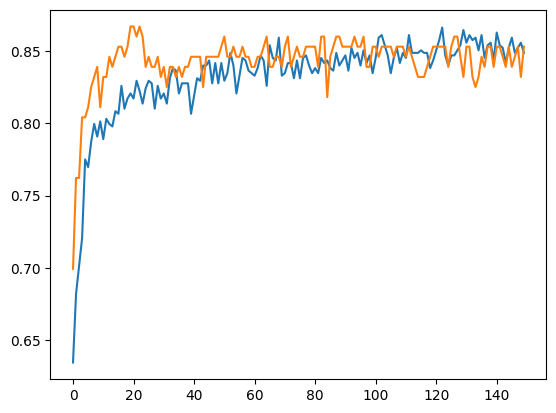

In [58]:
import matplotlib.pyplot as plt
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

In [59]:
from sklearn.metrics import accuracy_score

In [60]:
accuracy_score(y_test,y_pred)

0.8212290502793296